# 🏠 Predictive Insight Engine — House Price Prediction using Regression
**Author:** Ajay Sosa  |  **Role:** Junior Data Scientist @ Real Estate Analytics Firm  |  **Duration:** 6 Hours

**Objective:** Understand, implement and evaluate supervised learning algorithms (Simple / Multiple / Polynomial Linear Regression), Gradient Descent optimisation and the bias–variance trade-off to predict house prices — and explain *why* certain models perform better than others.

**Notebook map:** Part A Theory → B Data preparation → C Simple LR → D Metrics → E Multiple LR → F Polynomial → G Gradient Descent → H Bias–Variance → I Final report.

# 🧠 Part A: Conceptual Understanding (Theory)

**1. What are Supervised Learning Algorithms?**
Supervised learning algorithms learn a mapping from input features (X) to a known target (y) using *labelled* training data. After learning, they predict y for new, unseen inputs. Examples: Linear Regression, Logistic Regression, Decision Trees, SVM.

**2. Regression vs Classification**
- **Regression** predicts a *continuous numeric* value (e.g. house price in ₹, temperature). Evaluated with MSE, RMSE, MAE, R².
- **Classification** predicts a *discrete class/label* (e.g. spam / not spam). Evaluated with accuracy, precision, recall, F1.

**3. Simple Linear Regression**
Models the relationship between **one** independent variable and a continuous target with a straight line: `y = β₀ + β₁x + ε`. β₀ is the intercept, β₁ the slope (change in y per unit x). The parameters are found by minimising the sum of squared errors (Ordinary Least Squares).

**4. Assumptions of Linear Regression**
1. **Linearity** – the relationship between X and y is linear.
2. **Independence** – residuals (errors) are independent of each other (no autocorrelation).
3. **Homoscedasticity** – residuals have constant variance across all fitted values.
4. **Normality of residuals** – errors are approximately normally distributed (matters for inference/confidence intervals).
5. **No multicollinearity** (multiple regression) – predictors are not highly correlated with each other.

**5. Bias–Variance Trade-Off**
*Bias* = error from over-simplified assumptions (underfitting). *Variance* = error from sensitivity to the particular training sample (overfitting). Expected error ≈ Bias² + Variance + irreducible noise. Increasing model complexity lowers bias but raises variance; the best model balances both.

# 🧪 Part B: Dataset Understanding & Preparation

In [31]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True)

def save_figure(name):
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv("data/RealEstate_HousePrice_Dataset_4200.csv")
print("Shape:", df.shape)
display(df.head())

Shape: (4200, 12)


,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6000,23,11.9000,5220,1,0,0,40275084
1,100002,1560,3,3,6.3000,13,15.8000,3882,1,0,13,26812029
2,100003,2071,4,3,5.8000,9,21.1000,4488,0,0,9,29315677
3,100004,2640,5,3,7.7000,12,7.9000,3614,1,1,4,47712959
4,100005,1498,3,3,3.8000,15,24.0000,2663,0,0,15,17724566


In [32]:
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate house_id:", df.house_id.duplicated().sum())
df.info()
display(df.describe().T)

Missing values per column:
 house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64 

Duplicate rows: 0 | Duplicate house_id: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-n

,count,mean,std,min,25%,50%,75%,max
house_id,"4,200.0000","102,100.5000","1,212.5799","100,001.0000","101,050.7500","102,100.5000","103,150.2500","104,200.0000"
area_sqft,"4,200.0000","1,667.3574",630.3361,450.0000,"1,226.7500","1,660.0000","2,084.2500","4,202.0000"
bedrooms,"4,200.0000",3.6967,1.5742,1.0000,3.0000,4.0000,5.0000,7.0000
bathrooms,"4,200.0000",2.8274,1.1536,1.0000,2.0000,3.0000,4.0000,6.0000
location_score,"4,200.0000",5.6114,2.1409,1.0000,4.0000,5.7000,7.3000,10.0000
age_years,"4,200.0000",23.8295,13.9457,1.0000,13.0000,21.0000,32.0000,80.0000
distance_city_km,"4,200.0000",18.1862,8.6745,1.0000,11.8000,17.8000,24.2000,47.6000
lot_size_sqft,"4,200.0000","3,366.3290","1,658.2306",800.0000,"2,122.5000","3,188.0000","4,364.2500","12,938.0000"
has_garage,"4,200.0000",0.6424,0.4794,0.0000,0.0000,1.0000,1.0000,1.0000
has_pool,"4,200.0000",0.0962,0.2949,0.0000,0.0000,0.0000,0.0000,1.0000


### Task 7 – Independent vs Dependent variables
The problem statement lists these features: **House Area, Bedrooms, Bathrooms, Location Score, Age of Property** and the target **House Price**.
The dataset file also has extra columns (`distance_city_km`, `lot_size_sqft`, `has_garage`, `has_pool`, `renovation_years_ago`) and an identifier `house_id` (not a feature – it is dropped).

| Role | Column(s) |
|---|---|
| **Dependent (target) variable** | `house_price_inr` |
| **Independent variables (core 5 – as specified in the brief)** | `area_sqft`, `bedrooms`, `bathrooms`, `location_score`, `age_years` |
| Extra columns (used only in an *extended* experiment in Part E) | `distance_city_km`, `lot_size_sqft`, `has_garage`, `has_pool`, `renovation_years_ago` |

The whole project uses the **5 core features**; Part E additionally shows what happens if all 10 columns are used.

In [33]:
TARGET = "house_price_inr"
FEATURES = ["area_sqft", "bedrooms", "bathrooms", "location_score", "age_years"]            # core features from the brief
EXTRA = ["distance_city_km", "lot_size_sqft", "has_garage", "has_pool", "renovation_years_ago"]
ALL_FEATURES = FEATURES + EXTRA

print("Dependent variable  :", TARGET)
print("Independent variables:", FEATURES)

Dependent variable  : house_price_inr
Independent variables: ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years']


### Task 8 – Visualise relationships between features and target

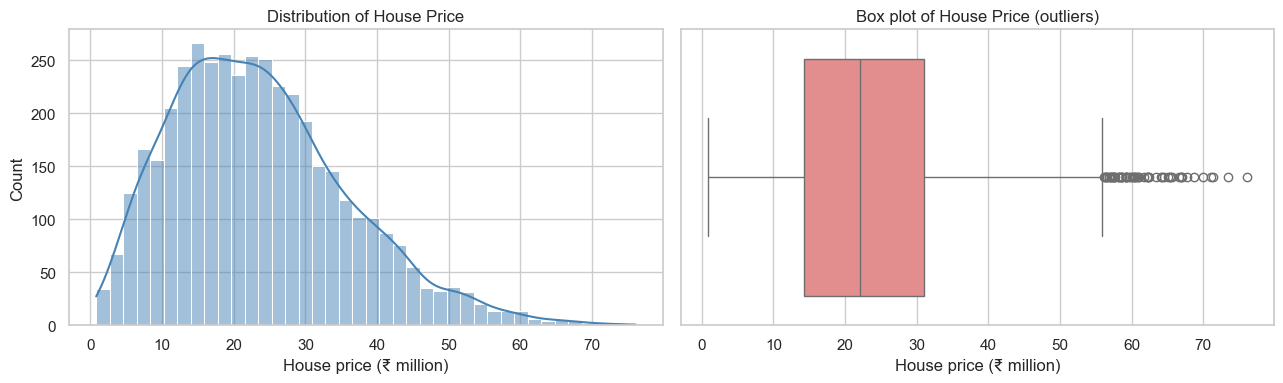

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET] / 1e6, bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of House Price"); axes[0].set_xlabel("House price (₹ million)")
sns.boxplot(x=df[TARGET] / 1e6, ax=axes[1], color="lightcoral")
axes[1].set_title("Box plot of House Price (outliers)"); axes[1].set_xlabel("House price (₹ million)")
plt.tight_layout(); save_figure("01_price_distribution"); plt.show()

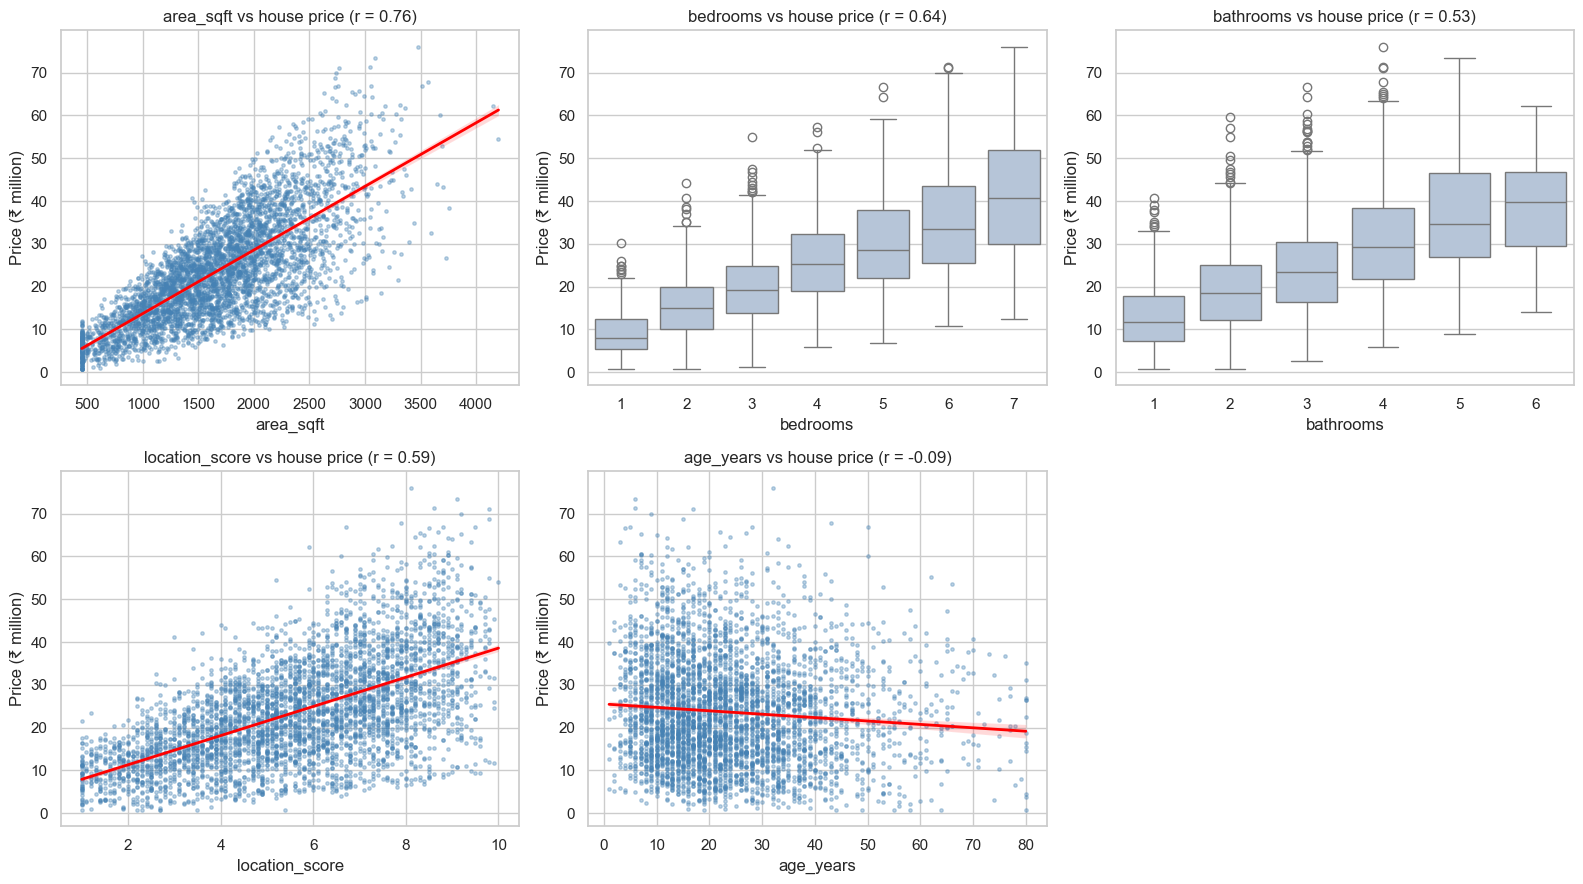

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9)); axes = axes.ravel()
for ax, f in zip(axes, FEATURES):
    if df[f].nunique() <= 10:   # discrete feature -> box plot is clearer
        sns.boxplot(x=df[f], y=df[TARGET] / 1e6, ax=ax, color="lightsteelblue")
    else:
        ax.scatter(df[f], df[TARGET] / 1e6, s=6, alpha=0.35, color="steelblue")
        sns.regplot(x=df[f], y=df[TARGET] / 1e6, scatter=False, ax=ax, color="red", line_kws={"lw": 2})
    ax.set_title(f"{f} vs house price (r = {df[f].corr(df[TARGET]):.2f})"); ax.set_ylabel("Price (₹ million)")
axes[-1].axis("off")
plt.tight_layout(); save_figure("02_feature_vs_price"); plt.show()

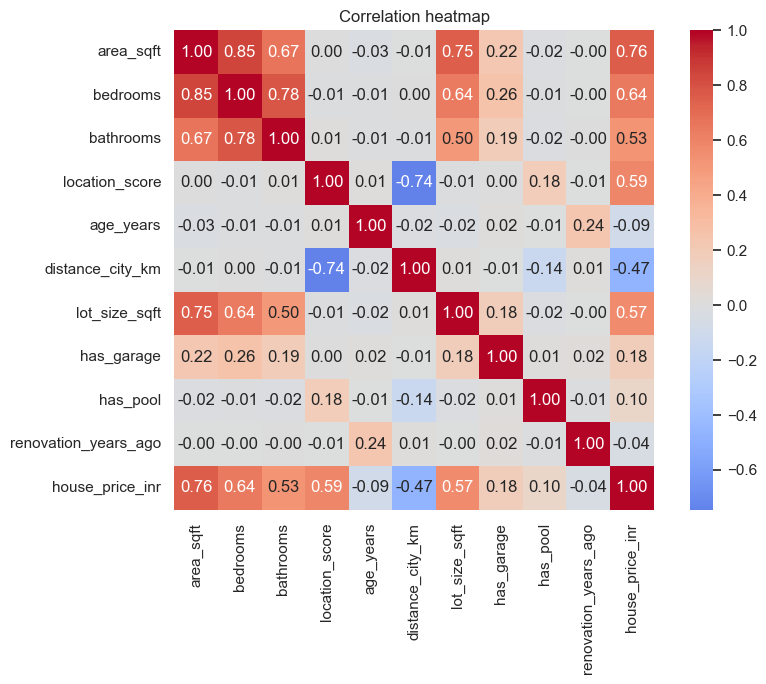

Correlation with price:
 area_sqft               0.7550
bedrooms                0.6450
location_score          0.5890
lot_size_sqft           0.5680
bathrooms               0.5270
has_garage              0.1770
has_pool                0.1020
renovation_years_ago   -0.0370
age_years              -0.0890
distance_city_km       -0.4690
Name: house_price_inr, dtype: float64


In [36]:
plt.figure(figsize=(9, 7))
corr = df[ALL_FEATURES + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap"); plt.tight_layout(); save_figure("03_correlation_heatmap"); plt.show()
print("Correlation with price:\n", corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

**Interpretation (Task 8):**
- Price is **right-skewed** with a few expensive houses (max ≈ ₹76.1 M) – typical for real-estate data; no missing values or duplicates were found, so no cleaning was needed.
- **`area_sqft`** has the strongest linear relationship with price (r = 0.76), followed by `bedrooms` (0.64), `location_score` (0.59) and `bathrooms` (0.53).
- `age_years` has a weak negative correlation (-0.09) – older houses are slightly cheaper, but age alone explains little.
- `area_sqft`, `bedrooms` and `bathrooms` are correlated with each other (bigger houses have more rooms) → possible **multicollinearity**, checked later with VIF.

### Task 9 – Split into training and testing sets
80 % of the data is used for training and 20 % is kept aside for testing (`random_state=42` for reproducibility). The test set is **never** used to fit anything.

In [37]:
X = df[FEATURES]; y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Training set :", X_train.shape, y_train.shape)
print("Testing set  :", X_test.shape, y_test.shape)

# the same split for the 10-feature experiment (same row indices)
Xa_train, Xa_test = df.loc[X_train.index, ALL_FEATURES], df.loc[X_test.index, ALL_FEATURES]

Training set : (3360, 5) (3360,)
Testing set  : (840, 5) (840,)


# 📈 Part C: Simple Linear Regression
### Task 10 – Implement Simple Linear Regression with one feature (`area_sqft`)

In [38]:
simple_model = LinearRegression().fit(X_train[["area_sqft"]], y_train)
slope, intercept = simple_model.coef_[0], simple_model.intercept_
print(f"Intercept (β0): ₹{intercept:,.0f}")
print(f"Slope     (β1): ₹{slope:,.2f} per sq.ft")
print(f"Equation: price = {intercept:,.0f} + {slope:,.2f} × area_sqft")

y_pred_slr_train = simple_model.predict(X_train[["area_sqft"]])
y_pred_slr = simple_model.predict(X_test[["area_sqft"]])

Intercept (β0): ₹-1,163,519
Slope     (β1): ₹14,788.31 per sq.ft
Equation: price = -1,163,519 + 14,788.31 × area_sqft


### Task 11 – Plot the regression line; interpret slope and intercept

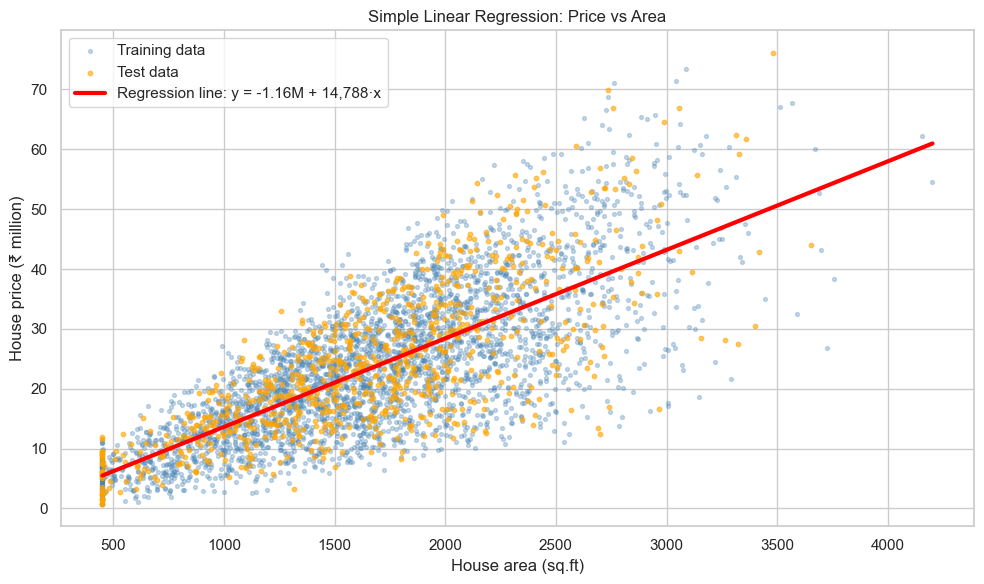

In [39]:
plt.figure(figsize=(10, 6))
plt.scatter(X_train["area_sqft"], y_train / 1e6, s=8, alpha=0.3, label="Training data", color="steelblue")
plt.scatter(X_test["area_sqft"], y_test / 1e6, s=10, alpha=0.6, label="Test data", color="orange")
area_grid = np.linspace(df.area_sqft.min(), df.area_sqft.max(), 200)
plt.plot(area_grid, simple_model.predict(pd.DataFrame({"area_sqft": area_grid})) / 1e6, color="red", lw=3,
         label=f"Regression line: y = {intercept/1e6:.2f}M + {slope:,.0f}·x")
plt.xlabel("House area (sq.ft)"); plt.ylabel("House price (₹ million)")
plt.title("Simple Linear Regression: Price vs Area"); plt.legend()
plt.tight_layout(); save_figure("04_slr_regression_line"); plt.show()

**Interpretation of the parameters**
- **Slope β₁ = ₹14,788 per sq.ft** → on average, every additional square foot adds about ₹14,788 to the price (holding nothing else constant – other features are ignored in this model).
- **Intercept β₀ = ₹-1,163,519** → the predicted price of a house with 0 sq.ft. This is just the line's starting point (extrapolation outside the data range, min area = 450 sq.ft, has no physical meaning).
- The points fan out around the line (wider spread for larger houses): area alone does not capture everything that drives price.

### Task 12 – Validate the linear-regression assumptions

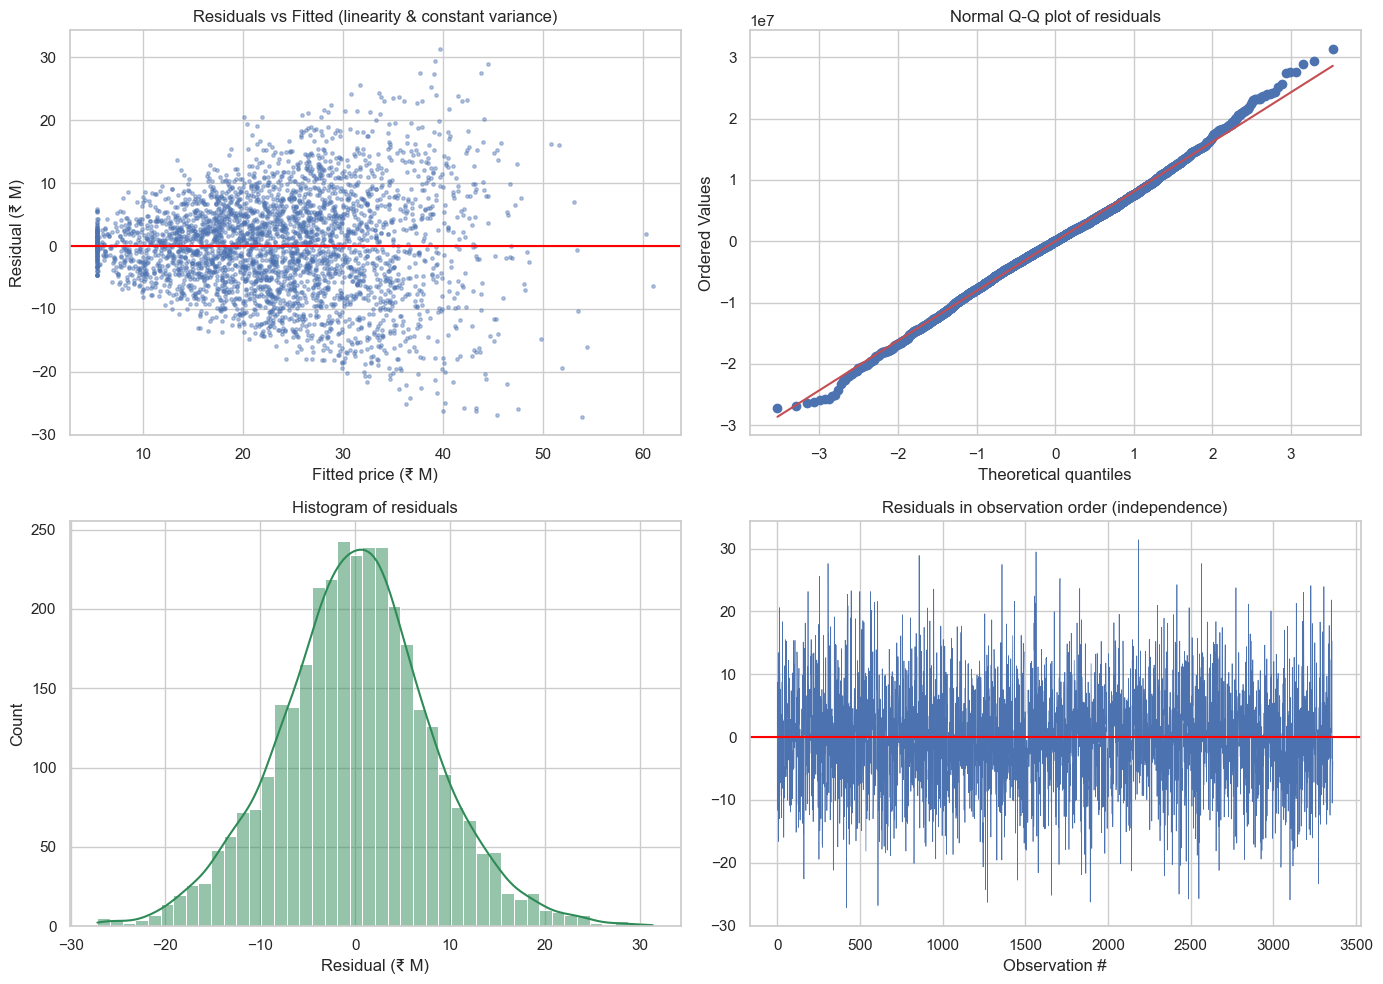

Durbin-Watson statistic      : 1.978  (≈2 → no autocorrelation)
Residual mean                : 0.00  (≈0)
Residual skewness / kurtosis : 0.037 / 0.431  (normal ≈ 0 / 0)
Corr(fitted, |residual|)     : 0.433  (>0 → variance grows with price = heteroscedasticity)


In [40]:
resid = y_train.values - y_pred_slr_train
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Linearity + 3) Homoscedasticity: residuals vs fitted
axes[0, 0].scatter(y_pred_slr_train / 1e6, resid / 1e6, s=6, alpha=0.4)
axes[0, 0].axhline(0, color="red"); axes[0, 0].set_title("Residuals vs Fitted (linearity & constant variance)")
axes[0, 0].set_xlabel("Fitted price (₹ M)"); axes[0, 0].set_ylabel("Residual (₹ M)")

# 4) Normality: Q-Q plot
stats.probplot(resid, dist="norm", plot=axes[0, 1]); axes[0, 1].set_title("Normal Q-Q plot of residuals")

# 4) Normality: histogram
sns.histplot(resid / 1e6, kde=True, ax=axes[1, 0], color="seagreen"); axes[1, 0].set_title("Histogram of residuals")
axes[1, 0].set_xlabel("Residual (₹ M)")

# 2) Independence: residuals in observation order
axes[1, 1].plot(resid / 1e6, lw=0.5); axes[1, 1].axhline(0, color="red")
axes[1, 1].set_title("Residuals in observation order (independence)"); axes[1, 1].set_xlabel("Observation #")
plt.tight_layout(); save_figure("05_slr_assumption_checks"); plt.show()

dw = np.sum(np.diff(resid) ** 2) / np.sum(resid ** 2)
skew, kurt = stats.skew(resid), stats.kurtosis(resid)
het_corr = np.corrcoef(y_pred_slr_train, np.abs(resid))[0, 1]
print(f"Durbin-Watson statistic      : {dw:.3f}  (≈2 → no autocorrelation)")
print(f"Residual mean                : {resid.mean():,.2f}  (≈0)")
print(f"Residual skewness / kurtosis : {skew:.3f} / {kurt:.3f}  (normal ≈ 0 / 0)")
print(f"Corr(fitted, |residual|)     : {het_corr:.3f}  (>0 → variance grows with price = heteroscedasticity)")

**Assumption check – observations**

| Assumption | Evidence | Verdict |
|---|---|---|
| Linearity | Scatter plot and residual plot show a broadly linear upward trend, no strong curve | ✅ Largely satisfied |
| Independence | Durbin-Watson = 1.98 (≈ 2) and no pattern in observation order | ✅ Satisfied |
| Homoscedasticity | Residual spread widens as fitted price rises; Corr(fitted, |resid|) = 0.43 | ⚠️ Violated (funnel shape) |
| Normality of residuals | Skewness = 0.04 and excess kurtosis = 0.43 are close to 0; histogram is bell-shaped and the Q-Q plot follows the line except slightly at the extremes | ✅ Approximately satisfied |

*Meaning:* the line is a reasonable average trend, but errors grow for expensive houses, so predictions for large houses are less reliable. A log-transformed target or additional features can reduce this — adding features is exactly what Part E does.

# 📊 Part D: Model Evaluation Metrics
### Task 13 – Evaluate the Simple Linear Regression model (MSE, MAE, RMSE, R², Adjusted R²)

`Adjusted R² = 1 − (1 − R²)·(n − 1)/(n − p − 1)` (n = samples, p = number of predictors). It penalises useless predictors.

In [41]:
def compute_metrics(y_true, y_pred, n_features):
    n = len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    adj = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    return {"MSE": mse, "MAE": mean_absolute_error(y_true, y_pred), "RMSE": np.sqrt(mse), "R2": r2, "Adj_R2": adj}

model_registry = {}          # model name -> {"train": {...}, "test": {...}}
def log_model(name, y_true_train, ptr, yte, pte, p):
    model_registry[name] = {"train": compute_metrics(y_true_train, ptr, p), "test": compute_metrics(yte, pte, p)}
    return pd.DataFrame(model_registry[name]).T

metrics_df = log_model("Simple Linear (area)", y_train, y_pred_slr_train, y_test, y_pred_slr, 1)
pd.options.display.float_format = "{:,.4f}".format
display(metrics_df)

,MSE,MAE,RMSE,R2,Adj_R2
train,"65,681,753,778,600.1562","6,291,402.3829","8,104,428.0353",0.5723,0.5722
test,"66,989,260,021,849.4688","6,294,593.6961","8,184,696.6970",0.5625,0.5620


### Task 14 – Interpret each metric

Test-set results of the Simple Linear Regression model:

| Metric | Value | What it tells us |
|---|---|---|
| **MSE** | 6.699e+13 | Average squared error (₹²). Huge in absolute terms because it squares rupee errors; it punishes big mistakes heavily and is mainly useful for comparing models. |
| **RMSE** | ₹8,184,697 | Square root of MSE, in ₹: a typical prediction error of about ₹8.2 M on a mean price of ₹23.6 M (≈ 35 % error) – quite large. |
| **MAE** | ₹6,294,594 | Average absolute error; less sensitive to outliers than RMSE. RMSE > MAE shows that some predictions are far off. |
| **R²** | 0.563 | Area explains only ≈ 56 % of the price variance; the remaining ≈ 44 % is due to other factors. |
| **Adjusted R²** | 0.562 | Almost equal to R² because there is only one predictor (no penalty); it becomes important when comparing models with different numbers of features. |

**Overall:** train and test scores are similar (no overfitting) but both are mediocre → the model **underfits** (high bias): one feature is not enough.

# 📉 Part E: Multiple Linear Regression
### Task 15 – Implement Multiple Linear Regression using all relevant features
All 5 core features from the brief are used: `area_sqft, bedrooms, bathrooms, location_score, age_years`.

In [42]:
multi_model = LinearRegression().fit(X_train, y_train)
coef_table = pd.DataFrame({"Feature": FEATURES, "Coefficient (₹ per unit)": multi_model.coef_})
print(f"Intercept: ₹{multi_model.intercept_:,.0f}")
display(coef_table)

y_pred_mlr_train, y_pred_mlr = multi_model.predict(X_train), multi_model.predict(X_test)
metrics_df = log_model("Multiple Linear (5 features)", y_train, y_pred_mlr_train, y_test, y_pred_mlr, len(FEATURES))
display(metrics_df)

Intercept: ₹-18,359,361


,Feature,Coefficient (₹ per unit)
0,area_sqft,"13,991.3825"
1,bedrooms,"205,468.2876"
2,bathrooms,"192,232.5333"
3,location_score,"3,385,623.3109"
4,age_years,"-67,607.6646"


,MSE,MAE,RMSE,R2,Adj_R2
train,"11,942,536,916,674.4883","2,610,145.2296","3,455,797.5804",0.9222,0.9221
test,"12,848,701,729,036.8984","2,641,320.3765","3,584,508.5757",0.9161,0.9156


In [43]:
# Multicollinearity check: Variance Inflation Factor (VIF = 1 / (1 - R²_j))
def compute_vif(Xdf):
    out = []
    for c in Xdf.columns:
        others = Xdf.drop(columns=c)
        r2 = LinearRegression().fit(others, Xdf[c]).score(others, Xdf[c])
        out.append((c, 1 / (1 - r2)))
    return pd.DataFrame(out, columns=["Feature", "VIF"])
display(compute_vif(X_train))

,Feature,VIF
0,area_sqft,3.5708
1,bedrooms,5.0531
2,bathrooms,2.5876
3,location_score,1.0013
4,age_years,1.0017


### Task 16 – Compare with Simple Linear Regression

,Train R2,Test R2,Test Adj R2,Test MAE,Test RMSE,Test MSE
Model,,,,,,
Simple Linear (area),0.5723,0.5625,0.5620,"6,294,593.6961","8,184,696.6970","66,989,260,021,849.4688"
Multiple Linear (5 features),0.9222,0.9161,0.9156,"2,641,320.3765","3,584,508.5757","12,848,701,729,036.8984"
"Multiple Linear (10 features, extended)",0.9247,0.9178,0.9168,"2,604,991.4062","3,548,650.2905","12,592,918,884,127.7422"


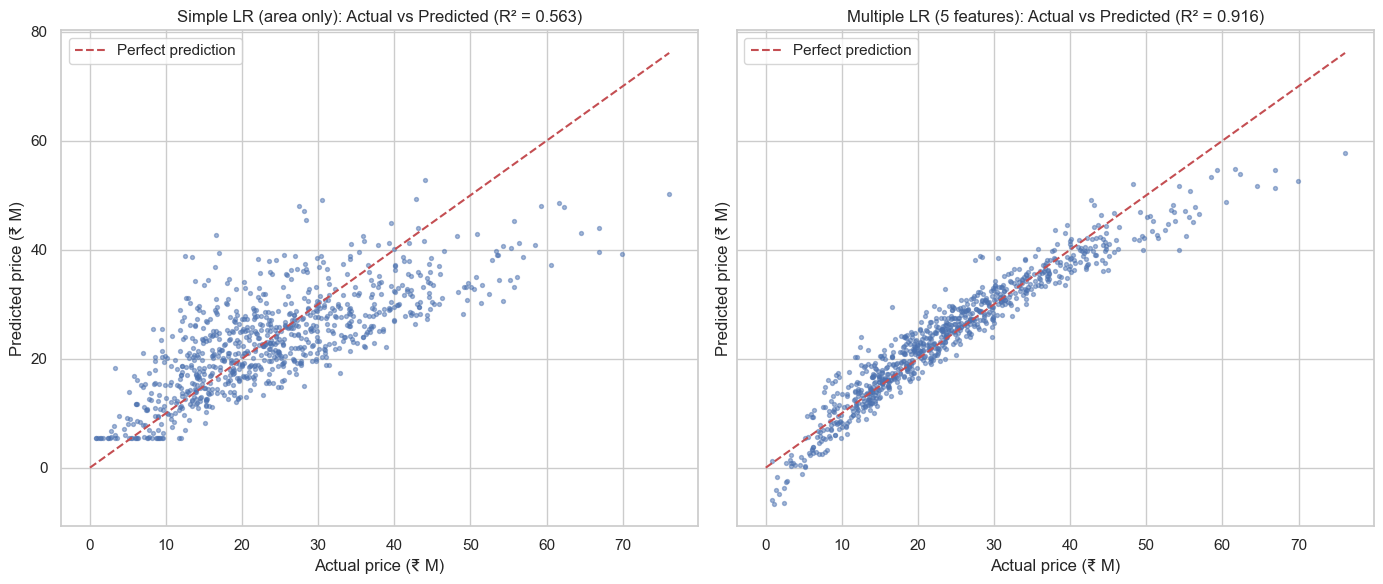

In [44]:
# Extended experiment: use all 10 columns
multi_model_all = LinearRegression().fit(Xa_train, y_train)
metrics_df = log_model("Multiple Linear (10 features, extended)", y_train, multi_model_all.predict(Xa_train), y_test, multi_model_all.predict(Xa_test), len(ALL_FEATURES))

def build_comparison_table(names):
    rows = []
    for n in names:
        r = model_registry[n]
        rows.append({"Model": n, "Train R2": r["train"]["R2"], "Test R2": r["test"]["R2"], "Test Adj R2": r["test"]["Adj_R2"],
                     "Test MAE": r["test"]["MAE"], "Test RMSE": r["test"]["RMSE"], "Test MSE": r["test"]["MSE"]})
    return pd.DataFrame(rows).set_index("Model")
display(build_comparison_table(["Simple Linear (area)", "Multiple Linear (5 features)", "Multiple Linear (10 features, extended)"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, pred, title in zip(axes, [y_pred_slr, y_pred_mlr], ["Simple LR (area only)", "Multiple LR (5 features)"]):
    ax.scatter(y_test / 1e6, pred / 1e6, s=8, alpha=0.5)
    lim = [0, y_test.max() / 1e6]; ax.plot(lim, lim, "r--", label="Perfect prediction")
    ax.set_title(f"{title}: Actual vs Predicted (R² = {r2_score(y_test, pred):.3f})")
    ax.set_xlabel("Actual price (₹ M)"); ax.set_ylabel("Predicted price (₹ M)"); ax.legend()
plt.tight_layout(); save_figure("06_slr_vs_mlr_actual_vs_pred"); plt.show()

### Task 17 – Why does performance improve?

Multiple Linear Regression raised the test R² from **0.563** to **0.916** and cut RMSE from ₹8.18 M to ₹3.58 M. Reasons:

1. **More information:** price depends on several factors (size, rooms, location quality, age). Using only area forces everything else into the error term → high bias / underfitting.
2. **Adjusted R² also rises** (0.562 → 0.916), so the gain is real and not just from adding more predictors.
3. **Omitted-variable bias is reduced:** e.g. `location_score` and `bedrooms` carry signal that area alone cannot provide; the slope of area becomes a cleaner "effect of area, *holding other features constant*".
4. **No overfitting:** train R² (0.922) ≈ test R² (0.916); the model generalises well.
5. **Multicollinearity** between area/bedrooms/bathrooms exists but VIFs are moderate (max VIF = 5.1 for bedrooms; all below the usual threshold of 10), so the model is usable, but the individual bedroom/bathroom coefficients should be read with some caution.
6. *Extension:* using all 10 columns gives only a small further gain (test R² = 0.918) – the extra columns add little *linear* information.

Note: age has a very small coefficient – a feature can be "relevant" yet weak. Performance would **degrade** if irrelevant/noisy or highly collinear features were added (adjusted R² would fall and variance would rise).

# 🔁 Part F: Polynomial Regression
### Task 18 – Implement Polynomial Regression (degree 2 and 3)
**(a) Single feature (`area_sqft`)** – lets us *see* the fitted curve. **(b) Multiple features** – polynomial terms and interactions of all 5 features (`StandardScaler → PolynomialFeatures → LinearRegression`).

In [45]:
def build_poly_pipeline(degree):
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())

# (a) single feature
for d in [1, 2, 3]:
    m = build_poly_pipeline(d).fit(X_train[["area_sqft"]], y_train)
    log_model(f"Poly deg {d} (area only)", y_train, m.predict(X_train[["area_sqft"]]), y_test, m.predict(X_test[["area_sqft"]]), d)
# (b) multiple features (number of predictors p = number of polynomial terms)
poly_models_5f = {}
for d in [1, 2, 3]:
    m = build_poly_pipeline(d).fit(X_train, y_train); poly_models_5f[d] = m
    p = m.named_steps["polynomialfeatures"].n_output_features_
    log_model(f"Poly deg {d} (5 features)", y_train, m.predict(X_train), y_test, m.predict(X_test), p)
    print(f"degree {d}: {p} polynomial terms")

degree 1: 5 polynomial terms
degree 2: 20 polynomial terms
degree 3: 55 polynomial terms


### Task 19 – Compare linear vs polynomial regression visually and numerically

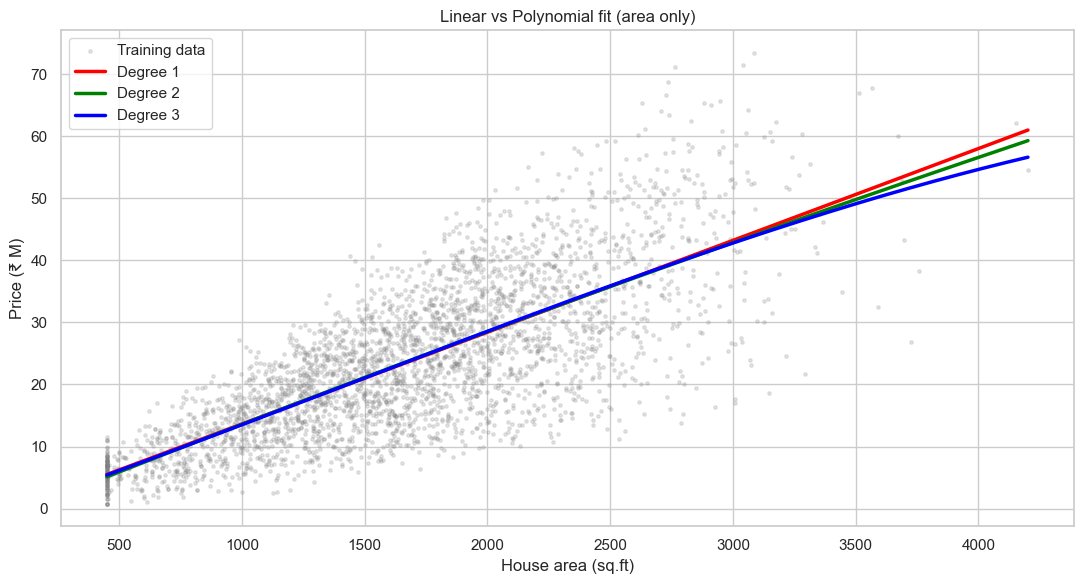

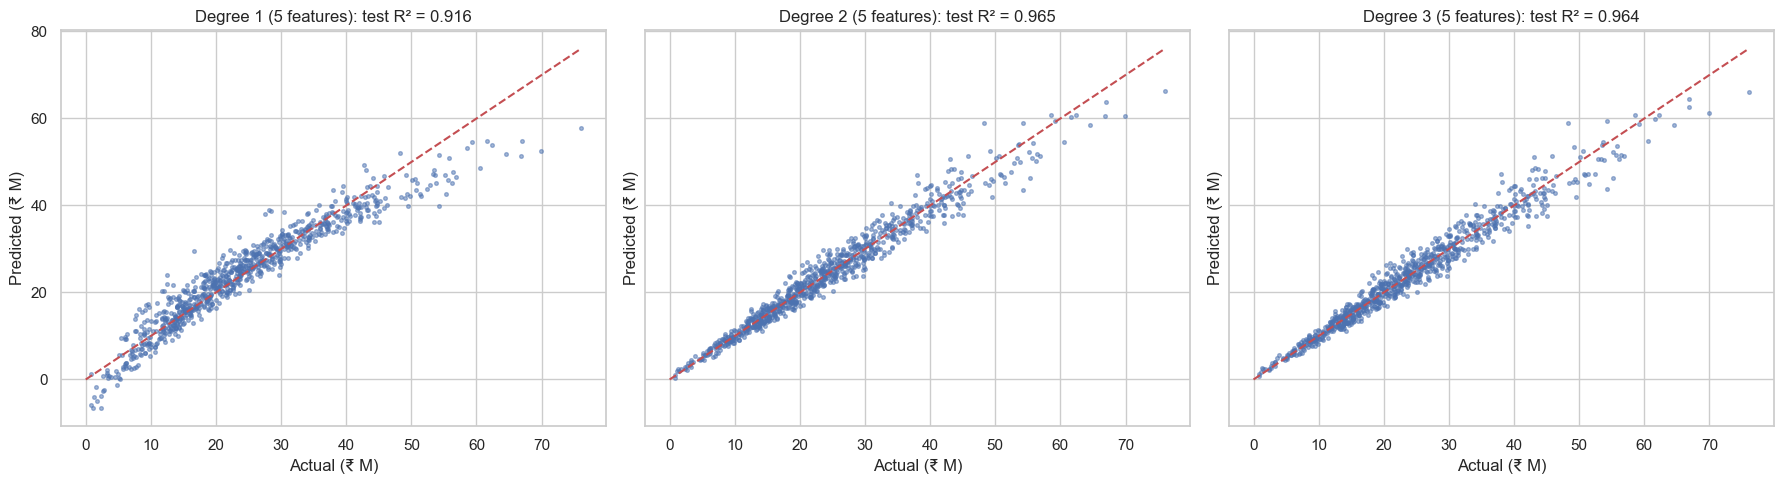

,Train R2,Test R2,Test Adj R2,Test MAE,Test RMSE,Test MSE
Model,,,,,,
Simple Linear (area),0.5723,0.5625,0.5620,"6,294,593.6961","8,184,696.6970","66,989,260,021,849.4688"
Poly deg 2 (area only),0.5725,0.5627,0.5616,"6,292,394.5613","8,183,089.0941","66,962,947,122,198.4609"
Poly deg 3 (area only),0.5726,0.5629,0.5613,"6,289,615.3147","8,181,382.2914","66,935,016,197,793.2344"
Multiple Linear (5 features),0.9222,0.9161,0.9156,"2,641,320.3765","3,584,508.5757","12,848,701,729,036.8984"
Poly deg 2 (5 features),0.9656,0.9645,0.9637,"1,715,218.8127","2,330,105.5805","5,429,392,016,489.5869"
Poly deg 3 (5 features),0.9663,0.9645,0.9620,"1,717,779.6933","2,331,837.6302","5,437,466,733,546.1250"


In [46]:
area_grid = pd.DataFrame({"area_sqft": np.linspace(df.area_sqft.min(), df.area_sqft.max(), 300)})
plt.figure(figsize=(11, 6))
plt.scatter(X_train["area_sqft"], y_train / 1e6, s=6, alpha=0.2, color="gray", label="Training data")
for d, c in zip([1, 2, 3], ["red", "green", "blue"]):
    m = build_poly_pipeline(d).fit(X_train[["area_sqft"]], y_train)
    plt.plot(area_grid.area_sqft, m.predict(area_grid) / 1e6, color=c, lw=2.5, label=f"Degree {d}")
plt.xlabel("House area (sq.ft)"); plt.ylabel("Price (₹ M)"); plt.title("Linear vs Polynomial fit (area only)"); plt.legend()
plt.tight_layout(); save_figure("07_poly_area_only"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (d, m) in zip(axes, poly_models_5f.items()):
    pred = m.predict(X_test)
    ax.scatter(y_test / 1e6, pred / 1e6, s=7, alpha=0.5)
    lim = [0, y_test.max() / 1e6]; ax.plot(lim, lim, "r--")
    ax.set_title(f"Degree {d} (5 features): test R² = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual (₹ M)"); ax.set_ylabel("Predicted (₹ M)")
plt.tight_layout(); save_figure("08_poly_multi_actual_vs_pred"); plt.show()

names = ["Simple Linear (area)", "Poly deg 2 (area only)", "Poly deg 3 (area only)",
         "Multiple Linear (5 features)", "Poly deg 2 (5 features)", "Poly deg 3 (5 features)"]
display(build_comparison_table(names))

### Task 20 – Signs of overfitting / underfitting
Two checks: (1) a **degree sweep** comparing train error vs test error vs 5-fold cross-validated error, and (2) a **small-sample stress test** (only 150 training rows) that makes overfitting visible.

Area only:


,Train RMSE,Test RMSE,CV RMSE,Train R2,Test R2
Degree,,,,,
1,"8,104,428.0353","8,184,696.6970","8,107,313.5025",0.5723,0.5625
2,"8,102,912.5206","8,183,089.0941","8,112,048.0658",0.5725,0.5627
3,"8,101,890.6833","8,181,382.2914","8,113,289.2633",0.5726,0.5629
4,"8,101,020.9207","8,181,471.9050","8,114,145.0012",0.5727,0.5629
5,"8,100,417.5852","8,182,590.7467","8,116,557.7737",0.5727,0.5627
6,"8,095,396.1622","8,190,982.5623","8,112,531.4319",0.5733,0.5618
7,"8,092,059.7454","8,196,818.1842","8,123,292.7687",0.5736,0.5612
8,"8,091,089.5958","8,191,220.4393","8,129,563.7087",0.5737,0.5618


5 features:


,Train RMSE,Test RMSE,CV RMSE,Train R2,Test R2
Degree,,,,,
1,"3,455,797.5804","3,584,508.5757","3,463,491.0058",0.9222,0.9161
2,"2,297,247.8655","2,330,105.5805","2,311,560.6732",0.9656,0.9645
3,"2,275,318.9567","2,331,837.6302","2,319,998.2418",0.9663,0.9645
4,"2,248,554.5633","2,353,271.9756","2,392,039.3560",0.9671,0.9638


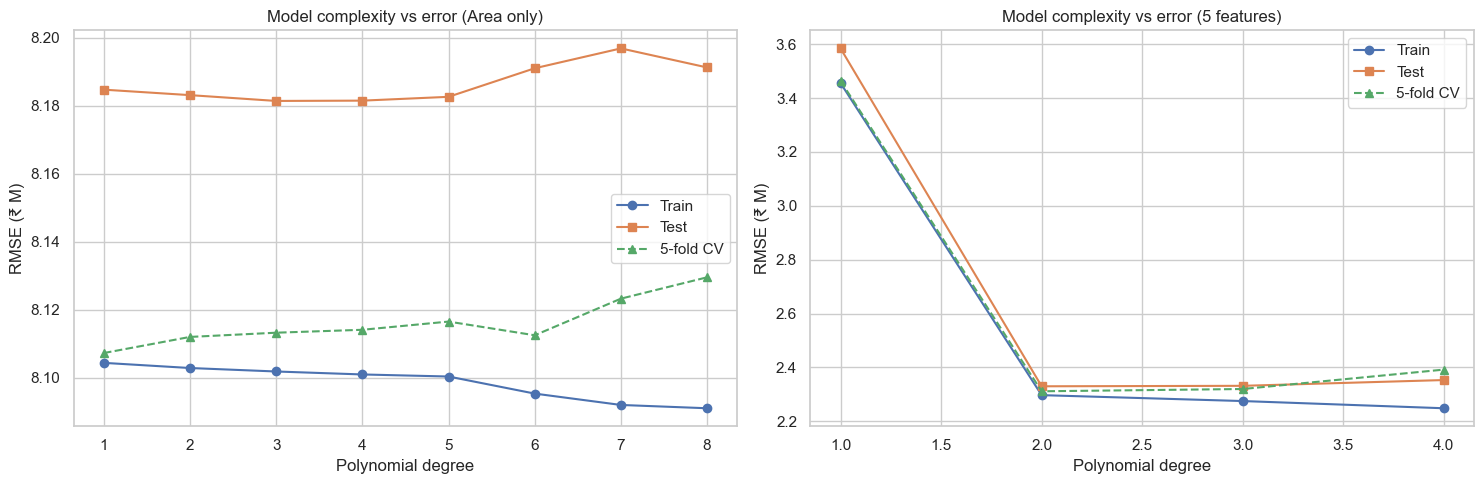

In [47]:
cv_splitter = KFold(5, shuffle=True, random_state=RANDOM_STATE)
def run_degree_sweep(cols, degrees):
    rows = []
    for d in degrees:
        m = build_poly_pipeline(d).fit(X_train[cols], y_train)
        cv = -cross_val_score(build_poly_pipeline(d), X_train[cols], y_train, cv=cv_splitter, scoring="neg_root_mean_squared_error").mean()
        rows.append({"Degree": d, "Train RMSE": np.sqrt(mean_squared_error(y_train, m.predict(X_train[cols]))),
                     "Test RMSE": np.sqrt(mean_squared_error(y_test, m.predict(X_test[cols]))), "CV RMSE": cv,
                     "Train R2": m.score(X_train[cols], y_train), "Test R2": m.score(X_test[cols], y_test)})
    return pd.DataFrame(rows).set_index("Degree")

degree_sweep_area = run_degree_sweep(["area_sqft"], range(1, 9))
degree_sweep_multi = run_degree_sweep(FEATURES, range(1, 5))
print("Area only:"); display(degree_sweep_area); print("5 features:"); display(degree_sweep_multi)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, sw, t in zip(axes, [degree_sweep_area, degree_sweep_multi], ["Area only", "5 features"]):
    ax.plot(sw.index, sw["Train RMSE"] / 1e6, "o-", label="Train"); ax.plot(sw.index, sw["Test RMSE"] / 1e6, "s-", label="Test")
    ax.plot(sw.index, sw["CV RMSE"] / 1e6, "^--", label="5-fold CV")
    ax.set_title(f"Model complexity vs error ({t})"); ax.set_xlabel("Polynomial degree"); ax.set_ylabel("RMSE (₹ M)"); ax.legend()
plt.tight_layout(); save_figure("09_complexity_vs_error"); plt.show()

In [48]:
# Small-sample stress test: train on only 150 rows, evaluate on the full untouched test set
small = X_train.sample(150, random_state=RANDOM_STATE).index
rows = []
for d in [1, 2, 3, 4]:
    m = build_poly_pipeline(d).fit(X_train.loc[small], y_train.loc[small])
    rows.append({"Degree": d, "Train R2": m.score(X_train.loc[small], y_train.loc[small]), "Test R2": m.score(X_test, y_test),
                 "Test RMSE": np.sqrt(mean_squared_error(y_test, m.predict(X_test)))})
small_sample_df = pd.DataFrame(rows).set_index("Degree"); display(small_sample_df)

,Train R2,Test R2,Test RMSE
Degree,,,
1,0.9300,0.9144,"3,619,383.6135"
2,0.9755,0.9583,"2,525,753.9893"
3,0.9824,0.9390,"3,056,630.6835"
4,0.9963,-1.7833,"20,644,552.9399"


**Observations (Task 20)**
- **Underfitting:** Simple linear / polynomial on *area only* have train R² ≈ test R² ≈ 0.56 for **every** degree – the curve hardly changes (see plot 07). The error is high for training *and* testing data → **high bias**; more polynomial terms of one feature cannot fix missing information.
- **Good fit:** with 5 features, going from degree 1 → 2 lowers test RMSE from ₹3.58 M to ₹2.33 M (test R² 0.916 → 0.965): the data contains interactions/curvature that a plane misses.
- **Beyond degree 2 no real gain:** degree 3 has train R² 0.9663 vs test R² 0.9645, degree 4 has 0.9671 vs 0.9638. Train score keeps creeping up while test/CV error stops improving or worsens → the first sign of **overfitting** (the gap widens as complexity grows).
- **Stress test with only 150 samples:** degree 4 reaches train R² = 0.996 but test R² = -1.783, versus test R² = 0.914 for degree 1 – a large train/test gap = clear **overfitting** when the model is too complex for the amount of data.

**Rule of thumb used:** underfitting = both errors high; overfitting = train error ≪ test error (and test/CV error rising with complexity).

# ⚙️ Part G: Gradient Descent Optimization
### Task 21 – Gradient Descent (concept)
**Gradient Descent** is an iterative optimisation algorithm that finds the model parameters **w** minimising a cost function. For linear regression the cost is the Mean Squared Error:

`J(w) = (1/2m) Σ (ŷᵢ − yᵢ)²,  with ŷ = Xw`

Idea (walking down a valley): compute the gradient (slope) of the cost with respect to each parameter, then take a small step in the *opposite* direction:

`w := w − α · ∇J(w),   ∇J(w) = (1/m) Xᵀ(Xw − y)`

- **α (learning rate):** too small → very slow; too large → overshoots and diverges.
- Because the MSE of linear regression is **convex**, GD converges to the global minimum (the same answer as the closed-form Normal Equation).
- **Feature scaling is essential** so all parameters have similar gradient magnitude and converge fast.

| Variant | Data used per update | Updates / epoch | Behaviour |
|---|---|---|---|
| **Batch GD** | all m samples | 1 | smooth, stable, slow per epoch on big data |
| **Stochastic GD (SGD)** | 1 random sample | m | very fast updates, noisy path, never fully settles at constant α |
| **Mini-Batch GD** | b samples (e.g. 64) | m / b | compromise: vectorised, fairly smooth, most used in practice |

All three are implemented **from scratch with NumPy** below on the 5-feature Multiple Linear Regression problem (standardised features and target).

In [49]:
# ---- Preprocessing for GD: standardise X and y using TRAINING statistics only ----
x_scaler = StandardScaler().fit(X_train)
X_tr_gd = np.c_[np.ones(len(X_train)), x_scaler.transform(X_train)]       # bias column of ones
X_te_gd = np.c_[np.ones(len(X_test)),  x_scaler.transform(X_test)]
y_mu, y_sd = y_train.mean(), y_train.std()
y_tr_gd = ((y_train - y_mu) / y_sd).values

def cost(X, y, w):                       # J(w) = 1/(2m) * sum((Xw - y)^2)
    r = X @ w - y
    return (r @ r) / (2 * len(y))

w_closed = np.linalg.lstsq(X_tr_gd, y_tr_gd, rcond=None)[0]   # exact solution (reference)
J_opt = cost(X_tr_gd, y_tr_gd, w_closed)
print("Optimal (closed-form) cost J* =", round(J_opt, 6))

Optimal (closed-form) cost J* = 0.038871


### Task 22 – Batch Gradient Descent from scratch

In [50]:
def batch_gd(X, y, lr=0.1, epochs=200):
    w = np.zeros(X.shape[1]); hist = [cost(X, y, w)]
    t0 = time.perf_counter()
    for _ in range(epochs):
        grad = X.T @ (X @ w - y) / len(y)        # gradient over the FULL dataset
        w -= lr * grad                           # one update per epoch
        hist.append(cost(X, y, w))
    return w, np.array(hist), time.perf_counter() - t0

w_bgd, h_bgd, t_bgd = batch_gd(X_tr_gd, y_tr_gd, lr=0.1, epochs=200)
print(f"Batch GD: final cost {h_bgd[-1]:.6f} | time {t_bgd:.4f}s | updates {200}")

Batch GD: final cost 0.038921 | time 0.0048s | updates 200


### Task 23 – Stochastic Gradient Descent (SGD) from scratch

In [51]:
def sgd(X, y, lr=0.01, epochs=30, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1]); hist = [cost(X, y, w)]
    t0 = time.perf_counter()
    for _ in range(epochs):
        for i in rng.permutation(len(y)):          # shuffle, then 1 sample per update
            xi = X[i]
            w -= lr * xi * (xi @ w - y[i])
        hist.append(cost(X, y, w))
    return w, np.array(hist), time.perf_counter() - t0

w_sgd, h_sgd, t_sgd = sgd(X_tr_gd, y_tr_gd, lr=0.01, epochs=30)
print(f"SGD: final cost {h_sgd[-1]:.6f} | time {t_sgd:.4f}s | updates {30*len(y_tr_gd):,}")

SGD: final cost 0.039826 | time 0.3809s | updates 100,800


### Task 24 – Mini-Batch Gradient Descent from scratch

In [52]:
def minibatch_gd(X, y, lr=0.05, epochs=50, batch_size=64, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1]); hist = [cost(X, y, w)]
    t0 = time.perf_counter()
    for _ in range(epochs):
        idx = rng.permutation(len(y))
        for s in range(0, len(y), batch_size):
            b = idx[s:s + batch_size]
            Xb, yb = X[b], y[b]
            w -= lr * Xb.T @ (Xb @ w - yb) / len(b)   # gradient on a small batch
        hist.append(cost(X, y, w))
    return w, np.array(hist), time.perf_counter() - t0

w_mbgd, h_mbgd, t_mbgd = minibatch_gd(X_tr_gd, y_tr_gd, lr=0.05, epochs=50, batch_size=64)
print(f"Mini-batch GD: final cost {h_mbgd[-1]:.6f} | time {t_mbgd:.4f}s | updates {50*int(np.ceil(len(y_tr_gd)/64)):,}")

Mini-batch GD: final cost 0.039015 | time 0.0310s | updates 2,650


### Task 25 – Compare convergence behaviour and training time

In [53]:
def epochs_to_converge(h, tol=0.01):          # first epoch where cost is within 1 % of the optimum
    ok = np.where(h <= J_opt * (1 + tol))[0]
    return int(ok[0]) if len(ok) else None

runs = {"Batch GD": (w_bgd, h_bgd, t_bgd, 1), "SGD": (w_sgd, h_sgd, t_sgd, len(y_tr_gd)),
        "Mini-Batch GD": (w_mbgd, h_mbgd, t_mbgd, int(np.ceil(len(y_tr_gd) / 64)))}
rows = []
for name, (w, h, t, upd) in runs.items():
    pred_tr = X_tr_gd @ w * y_sd + y_mu; pred_te = X_te_gd @ w * y_sd + y_mu
    log_model(name, y_train, pred_tr, y_test, pred_te, len(FEATURES))
    rows.append({"Method": name, "Epochs run": len(h) - 1, "Updates/epoch": upd, "Epochs to reach J*(1+1%)": epochs_to_converge(h),
                 "Final cost": h[-1], "Cost gap to optimum": h[-1] - J_opt, "Training time (s)": t,
                 "Test R2": model_registry[name]["test"]["R2"], "Test RMSE": model_registry[name]["test"]["RMSE"]})
gd_summary = pd.DataFrame(rows).set_index("Method"); display(gd_summary)

# parameters back on the original scale vs scikit-learn
params = pd.DataFrame({"sklearn (closed form)": np.r_[multi_model.intercept_, multi_model.coef_]},
                      index=["intercept"] + FEATURES)
for name, (w, *_ ) in runs.items():
    coef_orig = w[1:] * y_sd / x_scaler.scale_
    params[name] = np.r_[y_mu + y_sd * (w[0] - (w[1:] * x_scaler.mean_ / x_scaler.scale_).sum()), coef_orig]
display(params)

,Epochs run,Updates/epoch,Epochs to reach J*(1+1%),Final cost,Cost gap to optimum,Training time (s),Test R2,Test RMSE
Method,,,,,,,,
Batch GD,200,1,122,0.0389,0.0001,0.0048,0.9158,"3,589,913.8701"
SGD,30,3360,8,0.0398,0.0010,0.3809,0.9164,"3,578,544.8228"
Mini-Batch GD,50,53,6,0.0390,0.0001,0.0310,0.9151,"3,606,575.7271"


,sklearn (closed form),Batch GD,SGD,Mini-Batch GD
intercept,"-18,359,361.0926","-18,264,351.6727","-20,140,725.2046","-17,928,746.8984"
area_sqft,"13,991.3825","13,687.6612","14,045.3362","13,885.6125"
bedrooms,"205,468.2876","378,474.6745","324,723.3922","153,037.0507"
bathrooms,"192,232.5333","110,431.9073","347,103.4756","133,791.8104"
location_score,"3,385,623.3109","3,387,569.5238","3,560,165.1926","3,411,206.1564"
age_years,"-67,607.6646","-67,949.0046","-70,392.2936","-70,031.4309"


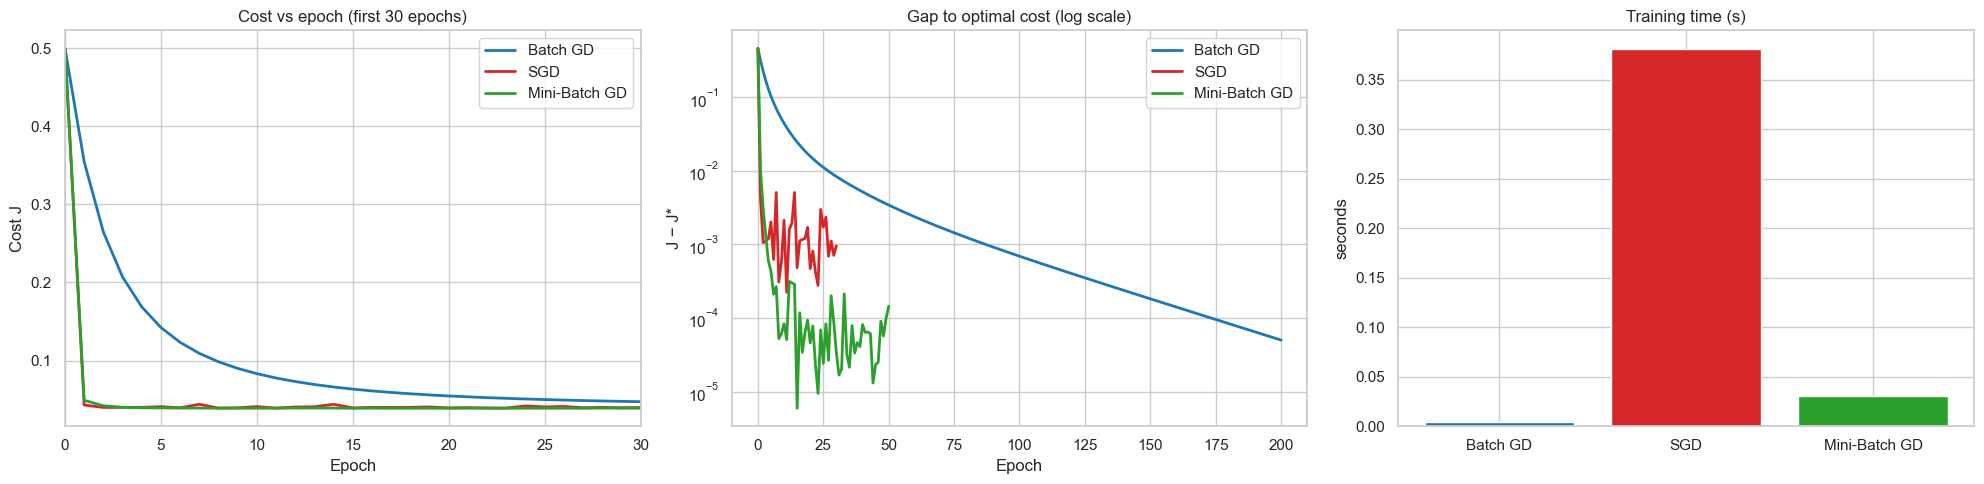

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
colors = {"Batch GD": "tab:blue", "SGD": "tab:red", "Mini-Batch GD": "tab:green"}
for name, (w, h, t, u) in runs.items():
    axes[0].plot(h, label=name, color=colors[name], lw=2)
    axes[1].plot(np.maximum(h - J_opt, 1e-12), label=name, color=colors[name], lw=2)
axes[0].set_xlim(0, 30); axes[0].set_title("Cost vs epoch (first 30 epochs)")
axes[1].set_yscale("log"); axes[1].set_title("Gap to optimal cost (log scale)")
for a in axes[:2]: a.set_xlabel("Epoch"); a.set_ylabel("Cost J"); a.legend()
axes[1].set_ylabel("J − J*")
axes[2].bar(list(runs), [r[2] for r in runs.values()], color=[colors[k] for k in runs])
axes[2].set_title("Training time (s)"); axes[2].set_ylabel("seconds")
plt.tight_layout(); save_figure("10_gd_convergence_comparison"); plt.show()

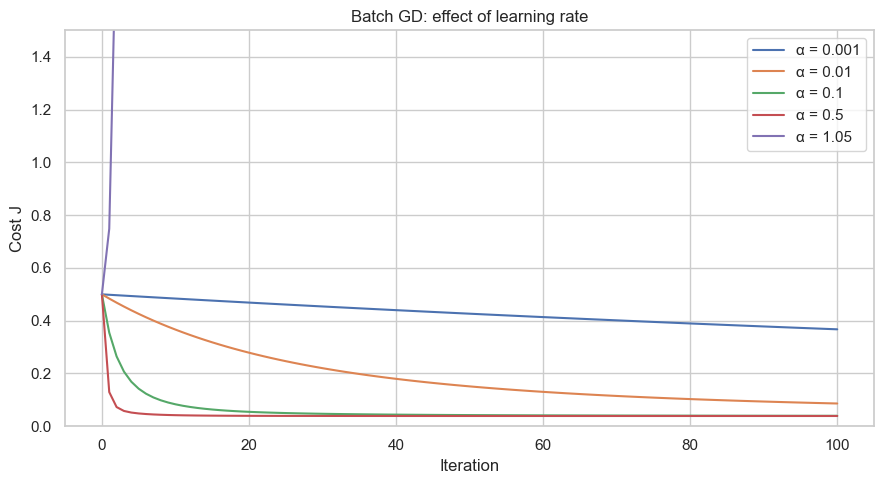

In [55]:
# Effect of learning rate on Batch GD (why alpha matters)
plt.figure(figsize=(9, 5))
for lr in [0.001, 0.01, 0.1, 0.5, 1.05]:
    _, h, _ = batch_gd(X_tr_gd, y_tr_gd, lr=lr, epochs=100)
    plt.plot(np.minimum(h, 5), label=f"α = {lr}")
plt.ylim(0, 1.5); plt.xlabel("Iteration"); plt.ylabel("Cost J"); plt.title("Batch GD: effect of learning rate"); plt.legend()
plt.tight_layout(); save_figure("11_gd_learning_rate"); plt.show()

**Convergence comparison – observations**

| | Batch GD | SGD | Mini-Batch GD |
|---|---|---|---|
| Epochs to get within 1 % of optimal cost | 122 | 8 | 6 |
| Training time | 0.006 s | 0.347 s | 0.027 s |
| Final cost gap to optimum | 5.00e-05 | 9.55e-04 | 1.44e-04 |
| Test R² | 0.9158 | 0.9164 | 0.9151 |

- **Batch GD** follows a smooth, monotonic curve (one accurate update per epoch) – but needs many epochs because each epoch is only *one* step.
- **SGD** makes 3,360 updates per epoch, so its cost drops very fast in the first epoch(s), but the path is **noisy** and keeps oscillating around the minimum (visible zig-zag / small gap) since it uses a constant learning rate. In pure Python it is the **slowest in wall-clock time** because of the per-sample loop.
- **Mini-Batch GD** gives the best compromise: fast epoch-wise convergence, much smoother than SGD, and vectorised batch operations make it quick per epoch.
- All three reach (almost) the **same cost and the same test performance as the closed-form solution**, and the strong coefficients (`area_sqft`, `location_score`, `age_years`) match closely (table above). Only the `bedrooms` / `bathrooms` coefficients differ noticeably: these two features are correlated (VIF ≈ 5), which creates a long, nearly flat valley in the cost surface, so many coefficient combinations give almost the same cost – GD stops at a slightly different point of that valley without losing accuracy. Gradient descent does not change *what* the best model is; it changes *how* we find it. This is why GD matters for models/datasets where no closed-form solution exists or the data is huge.
- Learning-rate plot: α = 0.001 is too slow, 0.1–0.5 converge quickly, and α ≈ 1 or larger **diverges** (cost explodes).

# 📐 Part H: Bias–Variance & Model Diagnostics
### Task 26 – Analyse bias and variance for Simple, Multiple and Polynomial Regression
**Method (empirical decomposition):** repeatedly (B = 100 times) draw a *bootstrap* training sample, fit the model and predict on the **same fixed test set**. Then
- `Bias²` = mean over test points of (average prediction − true value)² (includes the constant irreducible noise, which is identical for every model),
- `Variance` = mean over test points of the variance of the predictions across the B models,
- `Expected MSE = Bias² + Variance`.

Two settings are used: the **full training set** (n = 3,360) and a **small training set** (n = 200, sampled without replacement), where variance is easier to see.

In [56]:
def bias_variance(make_model, cols, n_boot=100, n_train=None, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    Xt, yt = X_test[cols], y_test.values
    preds = np.empty((n_boot, len(yt)))
    for b in range(n_boot):
        if n_train is None: idx = rng.integers(0, len(X_train), len(X_train))              # bootstrap sample
        else:               idx = rng.choice(len(X_train), n_train, replace=False)         # small sample
        m = make_model().fit(X_train.iloc[idx][cols], y_train.iloc[idx])
        preds[b] = m.predict(Xt)
    bias2 = np.mean((preds.mean(axis=0) - yt) ** 2)
    var = np.mean(preds.var(axis=0))
    return {"Bias²": bias2, "Variance": var, "Expected MSE": bias2 + var}

models_bv = {
    "Simple Linear (area)":        (lambda: LinearRegression(), ["area_sqft"]),
    "Multiple Linear (5 feat.)":   (lambda: LinearRegression(), FEATURES),
    "Polynomial deg 2 (5 feat.)":  (lambda: build_poly_pipeline(2), FEATURES),
    "Polynomial deg 3 (5 feat.)":  (lambda: build_poly_pipeline(3), FEATURES),
    "Polynomial deg 4 (5 feat.)":  (lambda: build_poly_pipeline(4), FEATURES),
}
rows = []
for name, (mk, cols) in models_bv.items():
    full = bias_variance(mk, cols); small_run = bias_variance(mk, cols, n_train=200)
    rows.append({"Model": name, "Bias² (n=3360)": full["Bias²"], "Variance (n=3360)": full["Variance"],
                 "Bias² (n=200)": small_run["Bias²"], "Variance (n=200)": small_run["Variance"], "Expected MSE (n=200)": small_run["Expected MSE"]})
bias_var_df = pd.DataFrame(rows).set_index("Model")
pd.options.display.float_format = "{:,.3e}".format
display(bias_var_df)
pd.options.display.float_format = "{:,.4f}".format

,Bias² (n=3360),Variance (n=3360),Bias² (n=200),Variance (n=200),Expected MSE (n=200)
Model,,,,,
Simple Linear (area),6.694e+13,3.597e+10,6.720e+13,6.463e+11,6.785e+13
Multiple Linear (5 feat.),1.285e+13,2.678e+10,1.283e+13,3.850e+11,1.322e+13
Polynomial deg 2 (5 feat.),5.426e+12,3.649e+10,5.442e+12,6.685e+11,6.110e+12
Polynomial deg 3 (5 feat.),5.426e+12,1.022e+11,5.495e+12,3.618e+12,9.113e+12
Polynomial deg 4 (5 feat.),5.526e+12,2.943e+11,7.186e+12,8.163e+13,8.881e+13


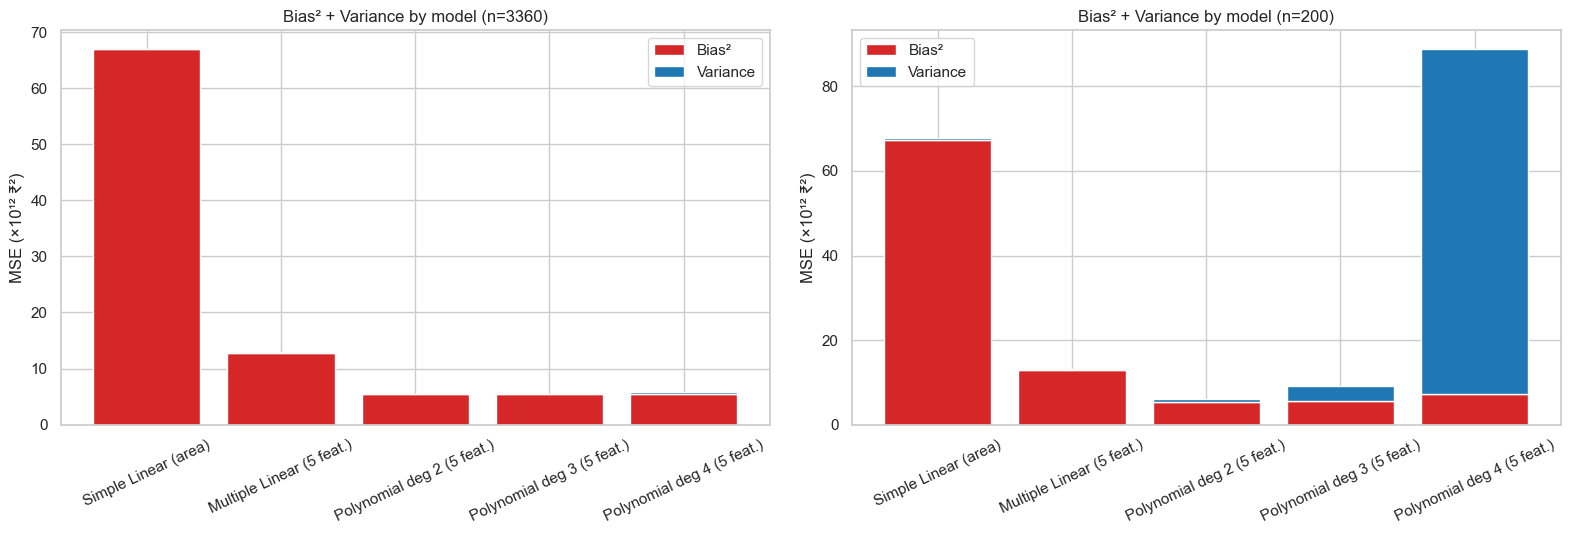

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, suffix in zip(axes, ["(n=3360)", "(n=200)"]):
    b, v = bias_var_df[f"Bias² {suffix}"] / 1e12, bias_var_df[f"Variance {suffix}"] / 1e12
    ax.bar(bias_var_df.index, b, label="Bias²", color="tab:red"); ax.bar(bias_var_df.index, v, bottom=b, label="Variance", color="tab:blue")
    ax.set_title(f"Bias² + Variance by model {suffix}"); ax.set_ylabel("MSE (×10¹² ₹²)")
    ax.tick_params(axis="x", rotation=25); ax.legend()
plt.tight_layout(); save_figure("12_bias_variance_decomposition"); plt.show()

### Task 27 – How model complexity affects prediction error
Combining the degree-sweep plot (Part F, fig. 09) with the decomposition above:

- **Low complexity (Simple Linear on area):** very high **bias²** (6.69e+13) and almost no variance → **underfitting**. Training and test error are both large.
- **Adding informative features (Multiple Linear):** bias² drops sharply (to 1.28e+13) while variance stays tiny – complexity bought us a lot of accuracy.
- **Adding non-linear terms/interactions (Polynomial deg 2):** bias² falls again (5.43e+12) because curvature/interactions in the data are captured; variance rises only slightly.
- **Too much complexity (deg 3–4):** bias² barely improves but **variance keeps growing** (n = 200: deg 2 = 6.69e+11 → deg 3 = 3.62e+12 → deg 4 = 8.16e+13). The model starts fitting sample-specific noise, so train error ↓ but test error stops improving (or rises) → **overfitting**.
- **Data size matters:** with 3,360 rows variance is small for all models; with only 200 rows complex models become unstable. More data lets you afford more complexity.

This is the classic **U-shaped test-error curve**: `Total error = Bias² + Variance + noise`; bias falls and variance rises as complexity increases, and the optimum lies in between.

### Task 28 – Which model best balances bias and variance?

In [58]:
summary = pd.DataFrame({
    "Test RMSE": {n: model_registry[n]["test"]["RMSE"] for n in ["Simple Linear (area)", "Multiple Linear (5 features)", "Poly deg 2 (5 features)", "Poly deg 3 (5 features)"]},
    "Train-Test R2 gap": {n: model_registry[n]["train"]["R2"] - model_registry[n]["test"]["R2"] for n in ["Simple Linear (area)", "Multiple Linear (5 features)", "Poly deg 2 (5 features)", "Poly deg 3 (5 features)"]},
})
summary["Expected MSE (n=200)"] = [bias_var_df.loc[k, "Expected MSE (n=200)"] for k in ["Simple Linear (area)", "Multiple Linear (5 feat.)", "Polynomial deg 2 (5 feat.)", "Polynomial deg 3 (5 feat.)"]]
summary["CV RMSE"] = [degree_sweep_area.loc[1, "CV RMSE"], degree_sweep_multi.loc[1, "CV RMSE"], degree_sweep_multi.loc[2, "CV RMSE"], degree_sweep_multi.loc[3, "CV RMSE"]]
pd.options.display.float_format = "{:,.4f}".format
display(summary)
best_model_name = "Poly deg 2 (5 features)"

,Test RMSE,Train-Test R2 gap,Expected MSE (n=200),CV RMSE
Simple Linear (area),"8,184,696.6970",0.0098,"67,850,853,490,212.7812","8,107,313.5025"
Multiple Linear (5 features),"3,584,508.5757",0.0061,"13,217,046,810,694.3789","3,463,491.0058"
Poly deg 2 (5 features),"2,330,105.5805",0.0011,"6,110,088,147,375.6025","2,311,560.6732"
Poly deg 3 (5 features),"2,331,837.6302",0.0018,"9,113,027,667,006.0781","2,319,998.2418"


**Conclusion (Task 28): Polynomial Regression of degree 2 on the 5 features** best balances bias and variance:
- Lowest (or statistically tied-lowest) **test RMSE ₹2.33 M** and CV RMSE ₹2.31 M.
- Train–test R² gap is tiny (0.0011) → low variance, no overfitting.
- Much lower bias than the linear models; degree 3 adds 35 more terms for no accuracy gain (and higher variance), so by the principle of parsimony degree 2 is preferred.
- Simple LR → too biased; Multiple LR → a strong, interpretable baseline; Poly deg 3+ → unnecessary complexity.

# 📝 Part I: Final Analysis & Reporting
### Task 29 – Findings: model leaderboard

,Train R2,Test R2,Test Adj R2,Test MAE,Test RMSE,Test MSE
Model,,,,,,
Poly deg 2 (5 features),0.9656,0.9645,0.9637,"1,715,218.8127","2,330,105.5805","5,429,392,016,489.5869"
Poly deg 3 (5 features),0.9663,0.9645,0.9620,"1,717,779.6933","2,331,837.6302","5,437,466,733,546.1250"
"Multiple Linear (10 features, extended)",0.9247,0.9178,0.9168,"2,604,991.4062","3,548,650.2905","12,592,918,884,127.7422"
SGD,0.9203,0.9164,0.9159,"2,697,499.0741","3,578,544.8228","12,805,983,049,128.1621"
Poly deg 1 (5 features),0.9222,0.9161,0.9156,"2,641,320.3765","3,584,508.5757","12,848,701,729,036.8984"
Multiple Linear (5 features),0.9222,0.9161,0.9156,"2,641,320.3765","3,584,508.5757","12,848,701,729,036.8984"
Batch GD,0.9221,0.9158,0.9153,"2,643,292.7233","3,589,913.8701","12,887,481,594,940.9707"
Mini-Batch GD,0.9219,0.9151,0.9145,"2,645,064.8409","3,606,575.7271","13,007,388,475,047.0996"
Poly deg 3 (area only),0.5726,0.5629,0.5613,"6,289,615.3147","8,181,382.2914","66,935,016,197,793.2344"


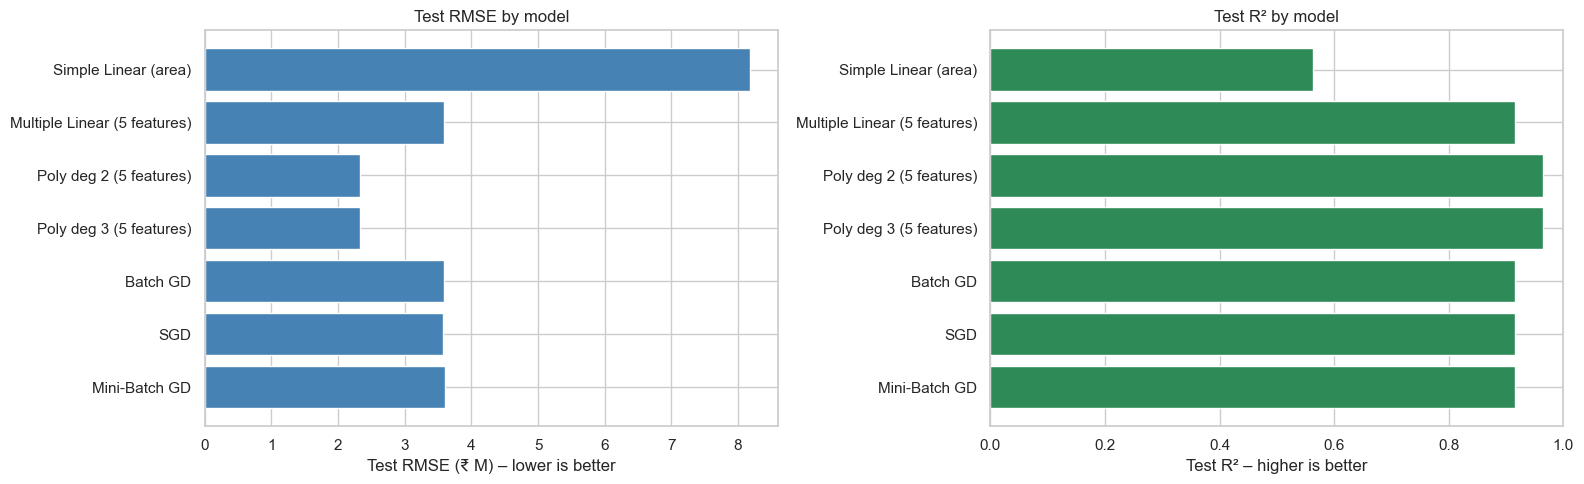

In [59]:
leaderboard = build_comparison_table(list(model_registry)).sort_values("Test RMSE")
pd.options.display.float_format = "{:,.4f}".format
display(leaderboard)
leaderboard.to_csv("results/model_evaluation_results.csv")
pd.DataFrame(model_registry["Poly deg 2 (5 features)"]).T.to_csv("results/best_model_metrics.csv")
gd_summary.to_csv("results/gradient_descent_comparison.csv"); bias_var_df.to_csv("results/bias_variance_decomposition.csv")
degree_sweep_multi.to_csv("results/degree_sweep_5_features.csv"); small_sample_df.to_csv("results/small_sample_overfitting_test.csv")

main = ["Simple Linear (area)", "Multiple Linear (5 features)", "Poly deg 2 (5 features)", "Poly deg 3 (5 features)", "Batch GD", "SGD", "Mini-Batch GD"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
t = leaderboard.loc[main]
axes[0].barh(t.index, t["Test RMSE"] / 1e6, color="steelblue"); axes[0].invert_yaxis(); axes[0].set_xlabel("Test RMSE (₹ M) – lower is better"); axes[0].set_title("Test RMSE by model")
axes[1].barh(t.index, t["Test R2"], color="seagreen"); axes[1].invert_yaxis(); axes[1].set_xlim(0, 1); axes[1].set_xlabel("Test R² – higher is better"); axes[1].set_title("Test R² by model")
plt.tight_layout(); save_figure("13_final_model_comparison"); plt.show()

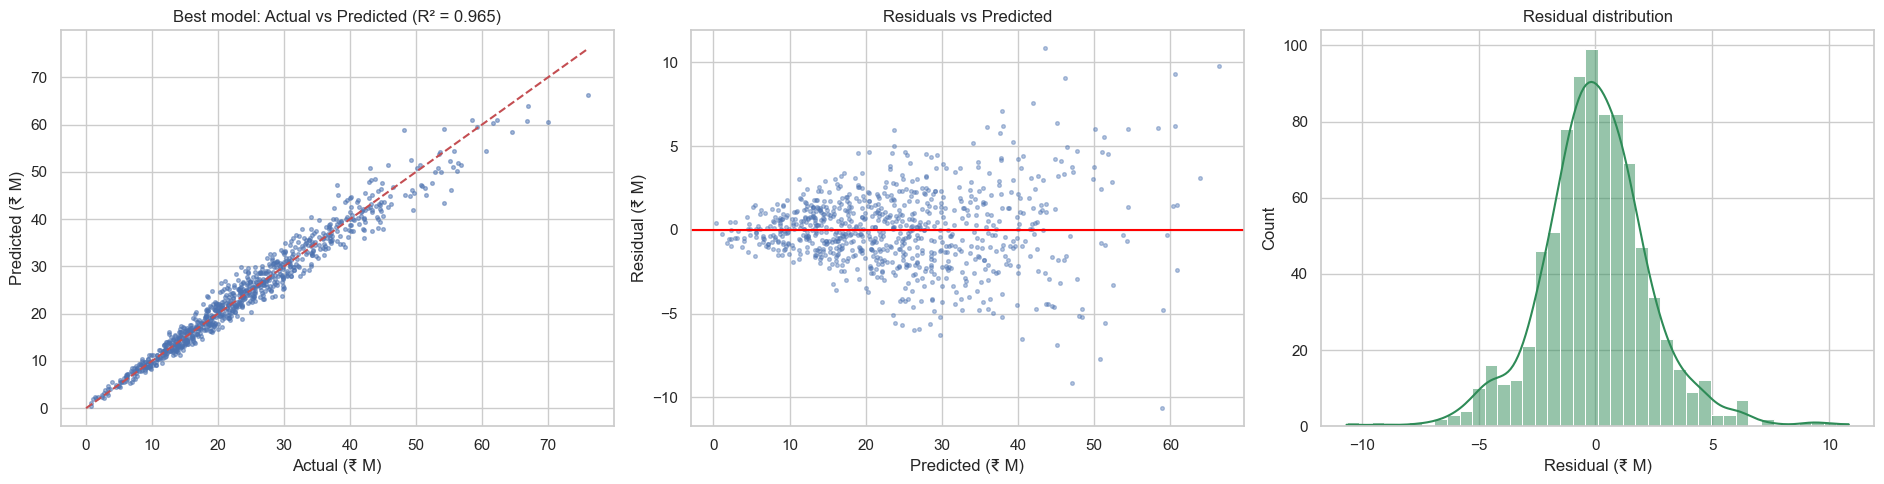

Example house (1800 sq.ft, 3 BHK, 2 bath, location 7.0, 10 yrs): estimated price ₹30,959,910
Typical error band (± RMSE): ₹28,629,805  to  ₹33,290,016


,"₹ change in price per +1 unit (Multiple LR, others fixed)"
area_sqft,"13,991.3825"
bedrooms,"205,468.2876"
bathrooms,"192,232.5333"
location_score,"3,385,623.3109"
age_years,"-67,607.6646"


In [60]:
# Diagnostics of the best model (Polynomial degree 2, 5 features)
best = poly_models_5f[2]; pb = best.predict(X_test); rb = y_test.values - pb
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].scatter(y_test / 1e6, pb / 1e6, s=7, alpha=0.5); lim = [0, y_test.max() / 1e6]; axes[0].plot(lim, lim, "r--")
axes[0].set_title(f"Best model: Actual vs Predicted (R² = {r2_score(y_test, pb):.3f})"); axes[0].set_xlabel("Actual (₹ M)"); axes[0].set_ylabel("Predicted (₹ M)")
axes[1].scatter(pb / 1e6, rb / 1e6, s=7, alpha=0.4); axes[1].axhline(0, color="red"); axes[1].set_title("Residuals vs Predicted"); axes[1].set_xlabel("Predicted (₹ M)"); axes[1].set_ylabel("Residual (₹ M)")
sns.histplot(rb / 1e6, kde=True, ax=axes[2], color="seagreen"); axes[2].set_title("Residual distribution"); axes[2].set_xlabel("Residual (₹ M)")
plt.tight_layout(); save_figure("14_best_model_diagnostics"); plt.show()

# Practical business interpretation
sample = pd.DataFrame([{"area_sqft": 1800, "bedrooms": 3, "bathrooms": 2, "location_score": 7.0, "age_years": 10}])
est = best.predict(sample)[0]
print(f"Example house (1800 sq.ft, 3 BHK, 2 bath, location 7.0, 10 yrs): estimated price ₹{est:,.0f}")
print(f"Typical error band (± RMSE): ₹{est - model_registry['Poly deg 2 (5 features)']['test']['RMSE']:,.0f}  to  ₹{est + model_registry['Poly deg 2 (5 features)']['test']['RMSE']:,.0f}")
mlr_effect = pd.Series(multi_model.coef_, index=FEATURES)
display(mlr_effect.rename("₹ change in price per +1 unit (Multiple LR, others fixed)").to_frame())

## Final Report (summary)

**1. Best-performing model and why**
The **Polynomial Regression (degree 2, 5 features)** is the best model: test R² = **0.965**, RMSE = **₹2.33 M**, MAE = ₹1.72 M, compared with R² = 0.563 (RMSE ₹8.18 M) for Simple Linear Regression and R² = 0.916 (RMSE ₹3.58 M) for Multiple Linear Regression.
It wins because (i) it uses all informative features, and (ii) its squared/interaction terms capture non-linear effects (e.g. area × location – a big house in a good location is worth disproportionately more) that a plane cannot, while (iii) the train–test gap stays tiny, so variance is under control.

**2. Impact of gradient descent optimisation**
Batch, Stochastic and Mini-Batch GD (all from scratch) converge to essentially the **same cost and the same test R² (0.9151–0.9164) as the closed-form solution** (Multiple Linear: 0.9161); GD does not make the model more accurate, it makes training *scalable*. Batch GD is smooth but slow per epoch, SGD is fast to start but noisy, Mini-Batch is the best trade-off. Feature scaling and a suitable learning rate (α) are essential – too large an α diverges.

**3. Evidence of overfitting / underfitting**
- *Underfitting:* Simple Linear (area only) – train R² ≈ test R² ≈ 0.56; polynomial terms of area alone do not help (high bias).
- *Overfitting:* with 5 features, degrees ≥ 3 raise train score but not test/CV score; in the small-sample test (150 rows) degree 4 gets train R² 1.00 but test R² -1.78.
- *Good fit:* Polynomial degree 2 (train R² 0.966 vs test R² 0.965).

**4. Practical business interpretation**
- The model typically predicts within about **₹1.7 M (MAE)** of the real price on a mean price of ₹23.6 M (≈ 7 % average error) – suitable for quick valuation, price benchmarking and screening listings; not a replacement for a professional appraisal.
- Linear-model effects (other features fixed): **+100 sq.ft ≈ +₹1.40 M**, **+1 location-score point ≈ +₹3.39 M**, **+1 bedroom ≈ +₹0.21 M**, **+1 bathroom ≈ +₹0.19 M**, **+1 year of age ≈ ₹-68 K**. Location quality and size are the most valuable levers.
- Example: a 1,800 sq.ft, 3-bed, 2-bath, location 7.0, 10-year-old house is estimated at **₹31.0 M** (± ≈ ₹2.3 M).
- Limitations: errors are larger for expensive houses (heteroscedasticity); the model ignores market timing, neighbourhood specifics and condition; predictions outside the observed ranges (area 450–4,200 sq.ft) are unreliable. Future work: log-transform the target, regularisation (Ridge/Lasso), tree-based models, the 5 extra columns.

### Task 30 – Submission checklist
| Item | Where |
|---|---|
| Source code | this notebook `Predictive_Insight_Engine.ipynb` |
| Model evaluation results | tables above + `results/model_evaluation_results.csv` |
| Graphs and plots | inline + `images/` folder (14 figures) |
| Final conclusion | below |

## ✅ Final Conclusion
House price is driven mainly by **size, bedrooms, location quality and bathrooms**; age matters little. A single-feature model underfits, adding the other features gives a large jump, and allowing degree-2 interactions gives the best generalisation. Higher-degree polynomials add variance without benefit. Gradient descent (Batch / SGD / Mini-Batch) reaches the same optimum as the analytical solution, with Mini-Batch being the most practical. **Recommended model: Polynomial Regression, degree 2, on the five core features.**